#Forecasting-challenge

##First we add the Necessary packages
###Then import the CSV files ,After that we do basic EDA Analysis

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action="ignore")

In [2]:
df_metadata = pd.read_csv("/content/vm_metadata.csv.gz")


In [3]:
df_cpu = pd.read_csv("/content/vm_cpu_readings.csv.gz")

In [4]:
print("Meta data Info : \n" )
df_metadata.info()
print("\n Cpu reading info :\n")
df_cpu.info()

Meta data Info : 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vm_id                 10000 non-null  object 
 1   subscription_id       10000 non-null  object 
 2   deployment_id         10000 non-null  object 
 3   timestamp_vm_created  10000 non-null  int64  
 4   timestamp_vm_deleted  10000 non-null  int64  
 5   max_cpu               10000 non-null  float64
 6   avg_cpu               10000 non-null  float64
 7   p95_max_cpu           10000 non-null  float64
 8   vm_category           10000 non-null  object 
 9   virtual_core_bucket   10000 non-null  object 
 10  memory_gb_bucket      10000 non-null  object 
dtypes: float64(3), int64(2), object(6)
memory usage: 859.5+ KB

 Cpu reading info :

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340000 entries, 0 to 1339999
Data columns (total 5 columns):
 #   Column 

In [5]:
print("MetaData_shape:",df_metadata.shape ,"\n Cpu_reading_shape", df_cpu.shape)

MetaData_shape: (10000, 11) 
 Cpu_reading_shape (1340000, 5)


In [6]:
print("Metadata null counts:\n", df_metadata.isnull().sum(), "\n\nCPU null counts:\n", df_cpu.isnull().sum())

Metadata null counts:
 vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64 

CPU null counts:
 timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64


In [7]:
print("check Both metadata and cpu_reading duplicate :",df_metadata.duplicated().sum(),"," ,df_cpu.duplicated().sum())

check Both metadata and cpu_reading duplicate : 0 , 0


In [8]:
df_metadata.head(5)

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


In [9]:
df_metadata.describe(include="all")

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
count,10000,10000,10000,10000.0,1.000000e+04,10000.000000,10000.000000,10000.000000,10000,10000,10000
unique,10000,2324,2359,NaN,NaN,NaN,NaN,NaN,3,5,6
top,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,0oKV+TK4WQnHX5gGsUKI3zdJThmjjpIqibzt/6i4vTuECO...,Utt3pKPVPLyiw8D5reQpxyRCno57dva7I1od0bXrWpVbI0...,NaN,NaN,NaN,NaN,NaN,Delay-insensitive,2,2
freq,1,96,96,NaN,NaN,NaN,NaN,NaN,6180,7534,3904
mean,NaN,NaN,NaN,0.0,2.289626e+06,86.492232,9.338249,36.365331,NaN,NaN,NaN
std,NaN,NaN,NaN,0.0,7.081008e+05,18.760321,11.253499,29.437773,NaN,NaN,NaN
min,NaN,NaN,NaN,0.0,4.050000e+04,0.028883,0.008060,0.025152,NaN,NaN,NaN
25%,NaN,NaN,NaN,0.0,2.591400e+06,82.299583,3.046473,10.591030,NaN,NaN,NaN
50%,NaN,NaN,NaN,0.0,2.591400e+06,95.423559,5.859044,23.975787,NaN,NaN,NaN
75%,NaN,NaN,NaN,0.0,2.591400e+06,98.381921,10.532403,62.029330,NaN,NaN,NaN


In [10]:
df_cpu.head(5)

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [11]:
df_cpu.describe(include="all")

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
count,1.340000e+06,1340000,1.340000e+06,1.340000e+06,1.340000e+06
unique,NaN,10000,NaN,NaN,NaN
top,NaN,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,NaN,NaN,NaN
freq,NaN,134,NaN,NaN,NaN
mean,1.995000e+04,NaN,6.156478e+00,1.834830e+01,9.388101e+00
std,1.160442e+04,NaN,1.175525e+01,2.161651e+01,1.426601e+01
min,0.000000e+00,NaN,0.000000e+00,1.810795e-02,7.158922e-03
25%,9.900000e+03,NaN,1.487979e+00,4.417642e+00,2.477060e+00
50%,1.995000e+04,NaN,3.227996e+00,9.124204e+00,5.105133e+00
75%,3.000000e+04,NaN,5.331087e+00,2.362418e+01,9.616715e+00


###Remove the Data leakage Values From the metadata Table


In [12]:
df_metadata_clean = df_metadata.drop(columns=["timestamp_vm_deleted", "max_cpu", "avg_cpu", "p95_max_cpu"])

###We grouped the data by timestamp to calculate total CPU usage and the number of running VMs every five minutes.
###After verifying the results, we visualized the trend.

In [13]:
df_target = df_cpu.groupby("timestamp",as_index=False).agg(active_vm_count=("vm_id", "nunique"),
    aggregate_cpu_utilization=("avg_cpu", "mean")
)

In [14]:
train_df = df_target.iloc[:110].copy()
test_df = df_target.iloc[110:].copy()

In [15]:
train_df.head(5)

,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503


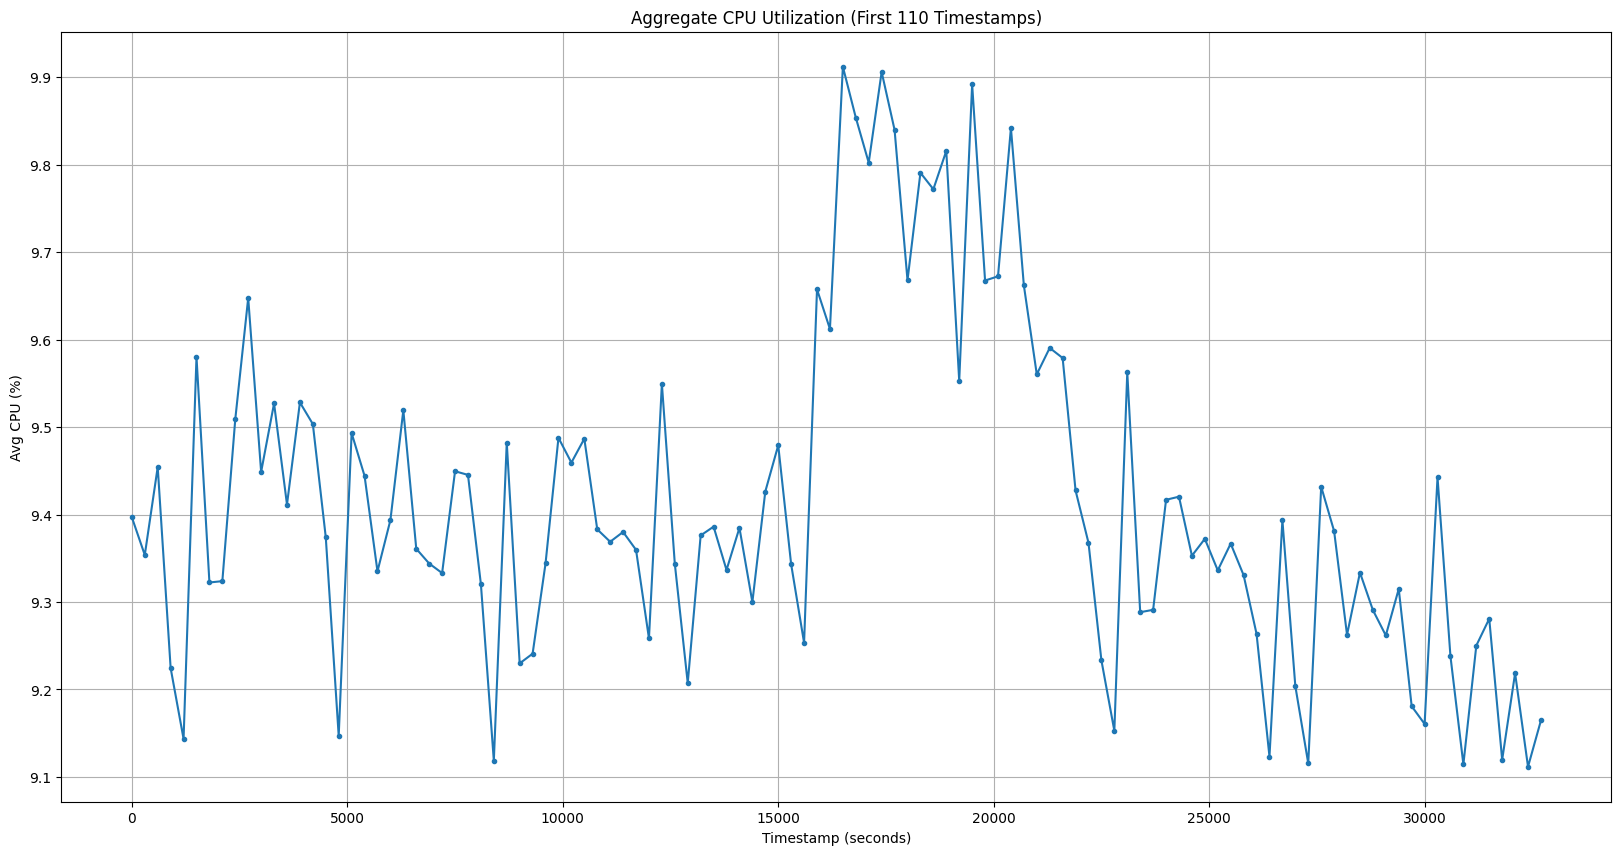

In [16]:
plt.figure(figsize=(20,10))
plt.plot(train_df['timestamp'],train_df['aggregate_cpu_utilization'],marker="o",markersize="3")
plt.title("Aggregate CPU Utilization (First 110 Timestamps)")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Avg CPU (%)")
plt.grid(True)
plt.show()

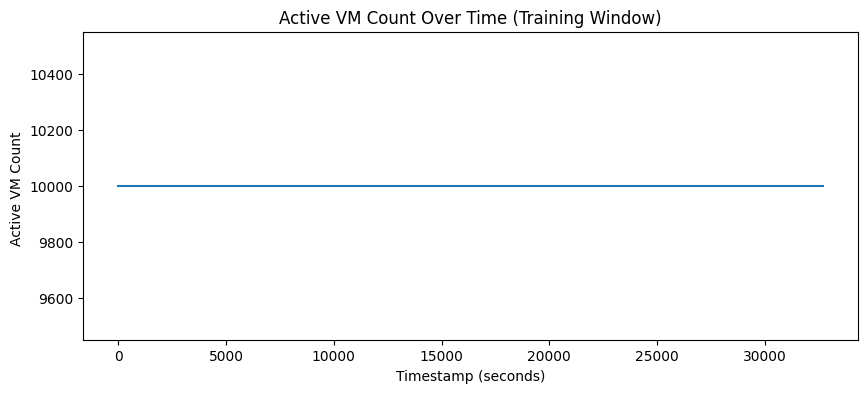

In [17]:
plt.figure(figsize=(10,4))
plt.plot(train_df['timestamp'],train_df['active_vm_count'])
plt.title("Active VM Count Over Time (Training Window)")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Active VM Count ")
plt.show()

### Filtered raw CPU data to keep only the training timestamps (train_cpu) so we can perform EDA without leaking test data.

In [18]:
train_cpu = df_cpu[df_cpu["timestamp"].isin(train_df["timestamp"])].copy()

In [19]:
train_cpu_merged = train_cpu.merge(df_metadata_clean, on="vm_id", how="left")

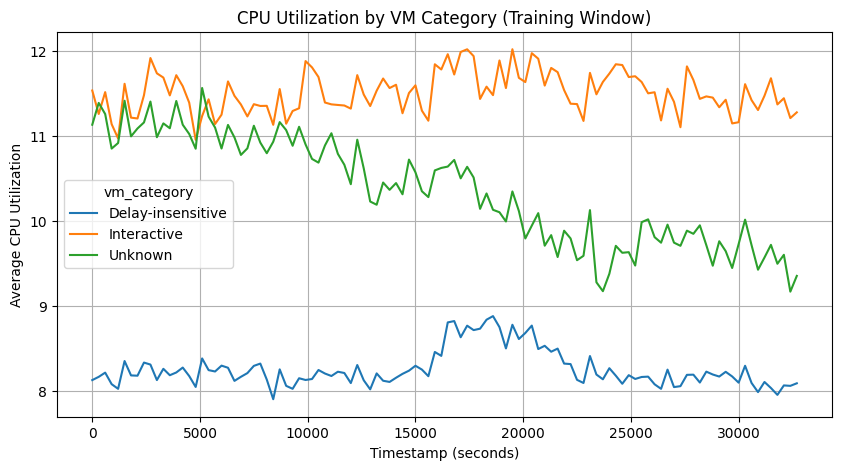

In [20]:
merge_cpu = train_cpu_merged.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()
merge_cpu.plot(figsize=(10,5),grid=True)
plt.title("CPU Utilization by VM Category (Training Window)")
plt.xlabel("Timestamp (seconds)")
plt.ylabel("Average CPU Utilization")
plt.show()

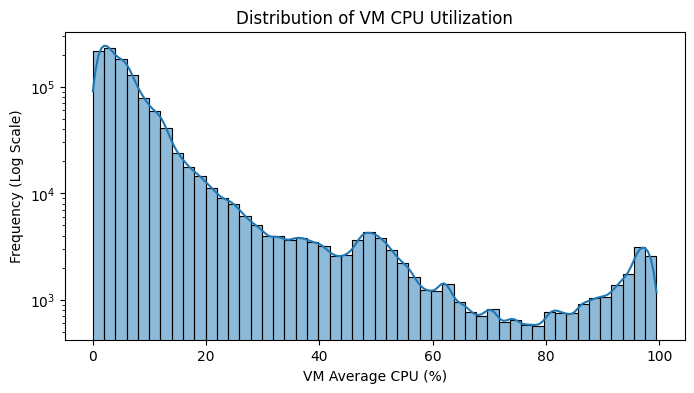

In [21]:
plt.figure(figsize=(8, 4))
sns.histplot(data=train_cpu_merged,x="avg_cpu",bins=50,kde=True)
plt.yscale("log")
plt.title("Distribution of VM CPU Utilization")
plt.xlabel("VM Average CPU (%)")
plt.ylabel("Frequency (Log Scale)")
plt.show()

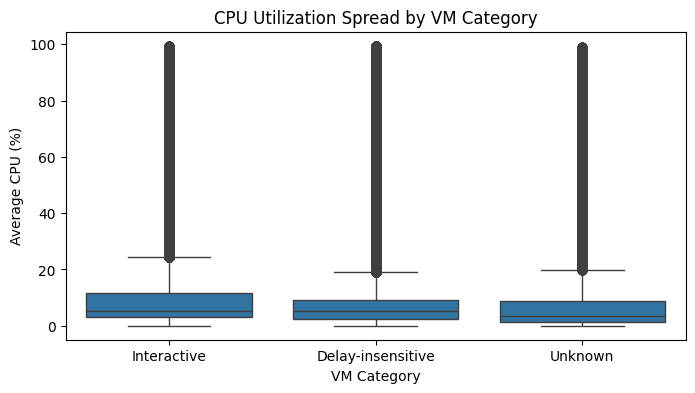

In [22]:
plt.figure(figsize=(8, 4))
sns.boxplot(x="vm_category", y="avg_cpu", data=train_cpu_merged)
plt.title("CPU Utilization Spread by VM Category")
plt.xlabel("VM Category")
plt.ylabel("Average CPU (%)")
plt.show()

###Find the  baseline of MAE and RMSE (Naive & Moving Average) as a benchmark before training ML models.

In [23]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error

In [24]:
y_test_cpu = test_df['aggregate_cpu_utilization']

In [25]:
y_pred_cpu_navie= [train_df['aggregate_cpu_utilization'].iloc[-1]]*len(y_test_cpu)
print("Navie Baseline \n Mean absolute error :",mean_absolute_error(y_test_cpu,y_pred_cpu_navie),"\n Root mean squared error:", root_mean_squared_error(y_test_cpu ,y_pred_cpu_navie))


Navie Baseline 
 Mean absolute error : 0.1467824591504233 
 Root mean squared error: 0.18478539074333666


In [26]:
y_pred_cpu_average = [train_df['aggregate_cpu_utilization'].iloc[-12].mean()]*len(y_test_cpu)
print("Average Baseline \n Mean absolute error :",mean_absolute_error(y_test_cpu,y_pred_cpu_average),"\n Root mean squared error:", root_mean_squared_error(y_test_cpu ,y_pred_cpu_average))


Average Baseline 
 Mean absolute error : 0.131513993338752 
 Root mean squared error: 0.15922730246570713


### Feature Engineering: Created lag features at 5, 10, 15, and 30-minute intervals (lag_1, lag_2, lag_3, lag_6) to capture short-term CPU trends and also remove the NaN values

In [27]:
df_feature = df_target.copy()

In [29]:
for lag in[1,2,3,6,12]:
  df_feature[f"lag_{lag}"] = df_feature['aggregate_cpu_utilization'].shift(lag)

In [30]:
df_feature.head(15)

,timestamp,active_vm_count,aggregate_cpu_utilization,lag_1,lag_2,lag_3,lag_6,lag_12
0,0,10000,9.396898,NaN,NaN,NaN,NaN,NaN
1,300,10000,9.353775,9.396898,NaN,NaN,NaN,NaN
2,600,10000,9.454383,9.353775,9.396898,NaN,NaN,NaN
3,900,10000,9.224419,9.454383,9.353775,9.396898,NaN,NaN
4,1200,10000,9.143503,9.224419,9.454383,9.353775,NaN,NaN
5,1500,10000,9.580335,9.143503,9.224419,9.454383,NaN,NaN
6,1800,10000,9.322337,9.580335,9.143503,9.224419,9.396898,NaN
7,2100,10000,9.323858,9.322337,9.580335,9.143503,9.353775,NaN
8,2400,10000,9.509058,9.323858,9.322337,9.580335,9.454383,NaN
9,2700,10000,9.647704,9.509058,9.323858,9.322337,9.224419,NaN


In [40]:
df_feature = df_feature.dropna()

In [41]:
df_feature.shape

(122, 8)

In [42]:
df_feature.isnull().sum()

,0
timestamp,0
active_vm_count,0
aggregate_cpu_utilization,0
lag_1,0
lag_2,0
lag_3,0
lag_6,0
lag_12,0


### Split the data in time order (first 98 steps for training, last 24 for testing) to avoid data leakage.

In [43]:
from sklearn.model_selection import train_test_split

In [57]:
x = df_feature.drop(['timestamp','aggregate_cpu_utilization'],axis=1)

In [59]:
y = df_feature['aggregate_cpu_utilization']

In [63]:
x_train = x.iloc[:-24]
x_test = x.iloc[-24:]

y_train = y.iloc[:-24]
y_test = y.iloc[-24:]

In [69]:
print(x_train.shape , x_test.shape)

(98, 6) (24, 6)


In [70]:
print(y_train.shape , y_test.shape)

(98,) (24,)


### Model Selection: Compared a simple linear model (Linear Regression) with a complex non‑linear model (Random Forest Regressor) to determine which better handles short‑term CPU patterns.

In [71]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [72]:
lireg = LinearRegression()
lireg.fit(x_train,y_train)

LinearRegression()

In [73]:
y_pred_lireg = lireg.predict(x_test)

In [75]:
print("MAE :",mean_absolute_error(y_test, y_pred_lireg))
print("RMSE :",root_mean_squared_error(y_test, y_pred_lireg))

MAE : 0.0751714944541592
RMSE : 0.11160439017190849


In [77]:
Rafg = RandomForestRegressor(random_state=42)
Rafg.fit(x_train,y_train)


RandomForestRegressor(random_state=42)

In [78]:
y_pred_Rafg = Rafg.predict(x_test)

In [79]:
print("MAE :",mean_absolute_error(y_test, y_pred_Rafg))
print("RMSE :",root_mean_squared_error(y_test, y_pred_Rafg))

MAE : 0.13865176230904078
RMSE : 0.17269578274134958


### Also Visualized Actual vs. Predicted CPU usage to see how accurately our models track the test data trends.

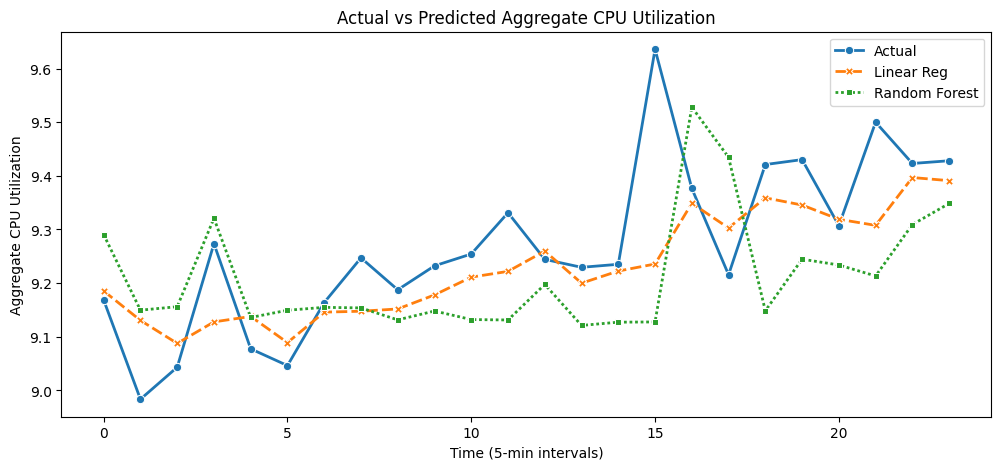

In [85]:
plt.figure(figsize=(12,5))
sns.lineplot(data={'Actual': y_test.values, 'Linear Reg': y_pred_lireg, 'Random Forest': y_pred_Rafg},markers=True, linewidth=2)
plt.title('Actual vs Predicted Aggregate CPU Utilization')
plt.xlabel('Time (5-min intervals)')
plt.ylabel('Aggregate CPU Utilization')
plt.show()

### Then we compare all the models to find the best one. After that, we save the model.

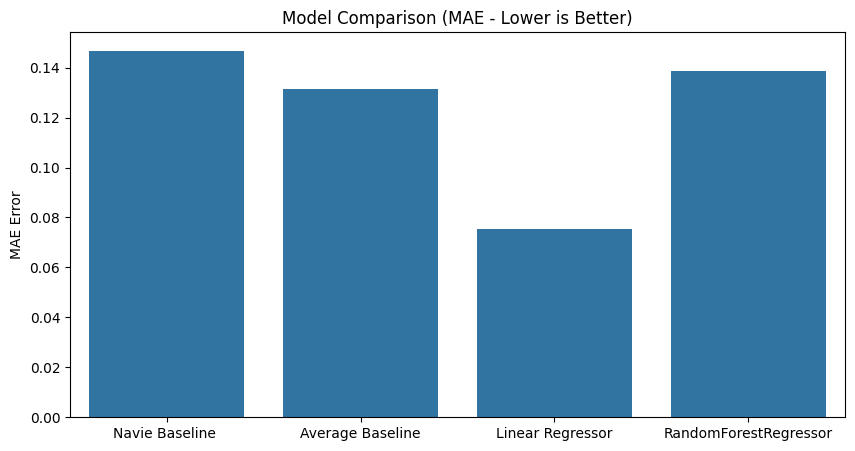

In [87]:
final_result = ['Navie Baseline ','Average Baseline','Linear Regressor','RandomForestRegressor']
final_mae_values =[0.1468,0.1315,0.0752,0.1387]
plt.figure(figsize=(10,5))
sns.barplot(x =final_result , y = final_mae_values)
plt.title('Model Comparison (MAE - Lower is Better)')
plt.ylabel('MAE Error')
plt.show()

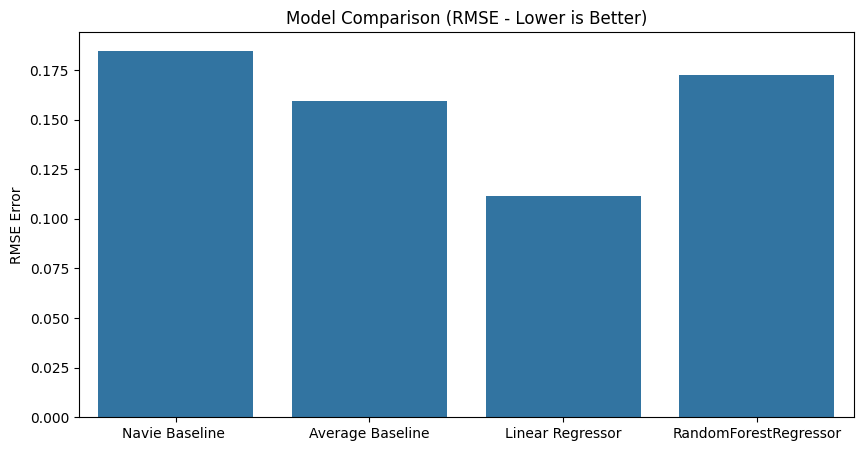

In [88]:
final_result = ['Navie Baseline ','Average Baseline','Linear Regressor','RandomForestRegressor']
final_rmse_values =[0.1848,0.1592,0.1116,0.1726]
plt.figure(figsize=(10,5))
sns.barplot(x =final_result , y = final_rmse_values)
plt.title('Model Comparison (RMSE - Lower is Better)')
plt.ylabel('RMSE Error')
plt.show()

## Save the Model


In [89]:
import joblib

In [90]:
joblib.dump(lireg,'cpu_forecast_linear_model.pkl')

['cpu_forecast_linear_model.pkl']